# Software Effort / Cost Estimation — Model Training & Evaluation

**Datasets:** 13 real PROMISE Software Engineering Repository datasets  
**Source:** http://promise.site.uottawa.ca/SERepository  
**License:** Published for reproducible, verifiable predictive modelling research.  
Cite PROMISE when publishing results.

---
**Integrity contract:** No synthetic data. Every number comes from the 13 files in `dataset/`.  
Metrics are computed **only** on held-out test rows that were never seen during training.

| Dataset | n | Target col | Unit |
|---------|---|-----------|------|
| Albrecht | 24 | Effort | person-months |
| China | 499 | Effort | person-hours |
| COCOMO-81 | 63 | actual | person-months |
| Desharnais | 81 | Effort | person-hours |
| Finnish | 38 | dev.eff.hrs. | person-hours |
| Kitchenham | 145 | Actual.effort | person-hours |
| Maxwell | 62 | Effort | person-hours |
| Miyazaki94 | 48 | MM | person-months |
| NASA93 | 93 | act_effort | person-months |
| Renzo-Pomodoro | ~10k usable | actual | pomodori |
| Subbiah | 29–72 | TotalLaborCost | USD |
| UCP_Dataset | 71 | Real_Effort_Person_Hours | person-hours |
| Valdes-Souto | 57 | Effort | person-hours |

## 0. Setup & Imports

In [1]:
import os, sys, hashlib, json, warnings, re
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats

from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge, HuberRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.neighbors import KNeighborsRegressor

try:
    import xgboost as xgb
    XGB_AVAILABLE = True
    print(f'XGBoost {xgb.__version__} available')
except ImportError:
    XGB_AVAILABLE = False
    print('XGBoost not installed — GradientBoosting will be used instead')

warnings.filterwarnings('ignore')
matplotlib.rcParams.update({'figure.dpi': 110, 'font.size': 10})
sns.set_theme(style='whitegrid', palette='muted')

DATASET_DIR  = Path('dataset')
RANDOM_SEED  = 42
np.random.seed(RANDOM_SEED)

print(f'Python {sys.version}')
print(f'pandas {pd.__version__} | numpy {np.__version__}')
assert DATASET_DIR.exists(), f'dataset/ folder not found at {DATASET_DIR.resolve()}'
print(f'Files in dataset/: {sorted(f.name for f in DATASET_DIR.iterdir())}')

XGBoost 3.4.1 available
Python 3.14.4 (tags/v3.14.4:23116f9, Apr  7 2026, 14:10:54) [MSC v.1944 64 bit (AMD64)]
pandas 3.0.6 | numpy 2.5.4
Files in dataset/: ['COCOMO-81.csv', 'Desharnais.csv', 'Subbiah.csv', 'UCP_Dataset.csv', 'Valdes-Souto.csv', 'albrecht.arff', 'china.arff', 'finnish.arff', 'kitchenham.arff', 'maxwell.arff', 'miyazaki94.arff', 'nasa93.arff', 'renzo-pomodoro.csv']


## 1. Custom ARFF Parser & Provenance

In [2]:
def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(65536), b''):
            h.update(chunk)
    return h.hexdigest()


def parse_arff(path_str: str) -> pd.DataFrame:
    """
    Robust ARFF reader that works for all 7 ARFF files in this dataset folder,
    including files with string attributes and tab-separated @attribute lines.
    Returns a DataFrame with clean column names.
    """
    text = Path(path_str).read_text(encoding='utf-8-sig', errors='replace')
    attrs = []
    data_rows = []
    in_data = False

    for line in text.splitlines():
        s = line.strip()
        if not s or s.startswith('%'):
            continue
        low = s.lower()
        if low.startswith('@attribute'):
            # Handle tab- or space-separated @attribute declarations
            parts = re.split(r'[\s\t]+', s, maxsplit=2)
            if len(parts) >= 2:
                attrs.append(parts[1].strip("'\" "))
        elif low.startswith('@data'):
            in_data = True
        elif in_data:
            data_rows.append([v.strip().strip('"') for v in s.split(',')])

    n = len(attrs)
    clean = []
    for row in data_rows:
        if len(row) >= n:
            clean.append(row[:n])
        elif row and any(v.strip() for v in row):
            clean.append(row + [''] * (n - len(row)))

    df = pd.DataFrame(clean, columns=attrs)
    # Replace ARFF missing value '?' with NaN
    df = df.replace({'?': np.nan, '': np.nan})
    return df


print('Custom ARFF parser and SHA-256 utility ready.')

Custom ARFF parser and SHA-256 utility ready.


## 2. Dataset Loaders

Each loader:
- Reads **only** the actual file on disk  
- Applies leakage guards (dropping columns derived from the target)  
- Returns a `dict` with `df`, `target`, `unit`, `sha256`

In [3]:
def _make(name, df, target, unit, path):
    """Pack loader output into a standard metadata dict."""
    df[target] = pd.to_numeric(df[target], errors='coerce')
    df = df[df[target] > 0].dropna(subset=[target]).reset_index(drop=True)
    return dict(name=name, df=df, target=target, unit=unit,
                source='PROMISE SERepo', sha256=sha256_file(path))


def load_albrecht():
    p = DATASET_DIR / 'albrecht.arff'
    df = parse_arff(str(p))
    # Columns: Input, Output, Inquiry, File, FPAdj, RawFPcounts, AdjFP, Effort
    for c in df.columns: df[c] = pd.to_numeric(df[c], errors='coerce')
    return _make('Albrecht', df, 'Effort', 'person-months', p)


def load_china():
    p = DATASET_DIR / 'china.arff'
    df = parse_arff(str(p))
    # Drop ID and N_effort (N_effort == Effort — duplicate)
    df = df.drop(columns=['ID', 'N_effort'], errors='ignore')
    for c in df.select_dtypes(include='object').columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return _make('China', df, 'Effort', 'person-hours', p)


def load_cocomo81():
    p = DATASET_DIR / 'COCOMO-81.csv'
    df = pd.read_csv(p)
    df.columns = df.columns.str.strip()
    df = df.drop(columns=['num'], errors='ignore')  # row ID
    return _make('COCOMO-81', df, 'actual', 'person-months', p)


def load_desharnais():
    p = DATASET_DIR / 'Desharnais.csv'
    df = pd.read_csv(p)
    df.columns = df.columns.str.strip()
    df = df.drop(columns=['id', 'Project'], errors='ignore')
    return _make('Desharnais', df, 'Effort', 'person-hours', p)


def load_finnish():
    p = DATASET_DIR / 'finnish.arff'
    df = parse_arff(str(p))
    df = df.drop(columns=['ID'], errors='ignore')
    # lnsize and lneff are log-transforms of FP and dev.eff.hrs. — drop (leakage)
    df = df.drop(columns=[c for c in df.columns if c.startswith('ln')], errors='ignore')
    for c in df.columns: df[c] = pd.to_numeric(df[c], errors='coerce')
    return _make('Finnish', df, 'dev.eff.hrs.', 'person-hours', p)


def load_kitchenham():
    p = DATASET_DIR / 'kitchenham.arff'
    df = parse_arff(str(p))
    # Drop identifier and date columns (not available at estimation time)
    df = df.drop(columns=['Project', 'Actual.start.date',
                           'Estimated.completion.date'], errors='ignore')
    # Numeric columns
    num_cols = ['Actual.duration', 'Actual.effort', 'Adjusted.function.points', 'First.estimate']
    for c in num_cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors='coerce')
    return _make('Kitchenham', df, 'Actual.effort', 'person-hours', p)


def load_maxwell():
    p = DATASET_DIR / 'maxwell.arff'
    df = parse_arff(str(p))
    # 'Time' = actual elapsed time (known only post-completion) — leakage, drop
    df = df.drop(columns=['Time'], errors='ignore')
    for c in df.columns: df[c] = pd.to_numeric(df[c], errors='coerce')
    return _make('Maxwell', df, 'Effort', 'person-hours', p)


def load_miyazaki94():
    p = DATASET_DIR / 'miyazaki94.arff'
    df = parse_arff(str(p))
    df = df.drop(columns=['ID'], errors='ignore')
    for c in df.columns: df[c] = pd.to_numeric(df[c], errors='coerce')
    return _make('Miyazaki94', df, 'MM', 'person-months', p)


def load_nasa93():
    p = DATASET_DIR / 'nasa93.arff'
    df = parse_arff(str(p))
    # Drop record number and project name
    df = df.drop(columns=['recordnumber', 'projectname'], errors='ignore')
    target = 'act_effort'
    num_cols = [c for c in df.columns if c != 'mode' and c != 'cat2'
                and c != 'forg' and c != 'center']
    for c in num_cols:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return _make('NASA93', df, target, 'person-months', p)


def load_renzo_pomodoro():
    p = DATASET_DIR / 'renzo-pomodoro.csv'
    df = pd.read_csv(p)
    df.columns = df.columns.str.strip().str.strip('"')
    target = 'actual'
    df[target]     = pd.to_numeric(df[target],    errors='coerce')
    df['estimate'] = pd.to_numeric(df['estimate'], errors='coerce')
    df = df.dropna(subset=[target, 'estimate'])
    df = df[(df[target] > 0) & (df['estimate'] > 0)].copy()
    # Pre-task features only — estimate is the key predictor
    df['word_cnt_proxy']  = df['word_cnt'].astype(str).apply(lambda x: x.count(',') + 1)
    df['description_len'] = pd.to_numeric(df['description'], errors='coerce').fillna(0)
    df['DONE']            = pd.to_numeric(df['DONE'], errors='coerce').fillna(0)
    df['date']            = pd.to_datetime(df['date'], errors='coerce')
    df['day_of_week']     = df['date'].dt.dayofweek.fillna(0).astype(int)
    keep = ['estimate', 'word_cnt_proxy', 'description_len', 'DONE', 'day_of_week', target]
    df = df[keep].dropna().reset_index(drop=True)
    return dict(name='Renzo-Pomodoro', df=df, target=target,
                unit='pomodori (25-min intervals)', source='PROMISE SERepo',
                sha256=sha256_file(p))


def load_subbiah():
    p = DATASET_DIR / 'Subbiah.csv'
    df = pd.read_csv(p)
    df.columns = df.columns.str.strip()
    # CostPerFP = TotalLaborCost / TotalUFP — derived from target (leakage)
    # Actual des = TotalLaborCost / Adjustment ... also leakage
    df = df.drop(columns=['Project', 'CostPerFP', 'Actual des'], errors='ignore')
    target = 'TotalLaborCost'
    for c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return _make('Subbiah', df, target, 'USD (labor cost)', p)


def load_ucp():
    p = DATASET_DIR / 'UCP_Dataset.csv'
    df = pd.read_csv(p, sep=';', decimal=',')
    df.columns = df.columns.str.strip()
    # Real_P20 = UCP * TCF * ECF * 20 — derived from target (leakage)
    df = df.drop(columns=['Project_No', 'Real_P20', 'DataDonator'], errors='ignore')
    target = 'Real_Effort_Person_Hours'
    for c in df.select_dtypes(include='object').columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return _make('UCP_Dataset', df, target, 'person-hours', p)


def load_valdes_souto():
    p = DATASET_DIR / 'Valdes-Souto.csv'
    df = pd.read_csv(p)
    df.columns = df.columns.str.strip()
    # HH_CFP = Effort / COSMIC_FP — derived from target (leakage)
    df = df.drop(columns=['Projct', 'ID', 'HH_CFP'], errors='ignore')
    for c in df.select_dtypes(include='object').columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return _make('Valdes-Souto', df, 'Effort', 'person-hours', p)


# ── Load all datasets ──────────────────────────────────────────────
LOADERS = [
    load_albrecht, load_china, load_cocomo81, load_desharnais,
    load_finnish, load_kitchenham, load_maxwell, load_miyazaki94,
    load_nasa93, load_renzo_pomodoro, load_subbiah, load_ucp, load_valdes_souto
]

all_datasets = {}
load_errors  = {}
for loader in LOADERS:
    try:
        meta = loader()
        all_datasets[meta['name']] = meta
        print(f"  ✓ {meta['name']:20s} n={len(meta['df']):5d}  "
              f"target={meta['target']}  unit={meta['unit']}")
    except Exception as exc:
        load_errors[loader.__name__] = str(exc)
        print(f"  ✗ {loader.__name__}: {exc}")

print(f'\nLoaded {len(all_datasets)}/{len(LOADERS)} datasets successfully.')
if load_errors:
    print('Load errors:', load_errors)

  ✓ Albrecht             n=   24  target=Effort  unit=person-months
  ✓ China                n=  499  target=Effort  unit=person-hours
  ✓ COCOMO-81            n=   63  target=actual  unit=person-months
  ✓ Desharnais           n=   81  target=Effort  unit=person-hours
  ✓ Finnish              n=   38  target=dev.eff.hrs.  unit=person-hours
  ✓ Kitchenham           n=  145  target=Actual.effort  unit=person-hours
  ✓ Maxwell              n=   62  target=Effort  unit=person-hours
  ✓ Miyazaki94           n=   48  target=MM  unit=person-months
  ✓ NASA93               n=   93  target=act_effort  unit=person-months
  ✗ load_renzo_pomodoro: 'float' object has no attribute 'count'
  ✓ Subbiah              n=   72  target=TotalLaborCost  unit=USD (labor cost)
  ✓ UCP_Dataset          n=   71  target=Real_Effort_Person_Hours  unit=person-hours
  ✓ Valdes-Souto         n=   57  target=Effort  unit=person-hours

Loaded 12/13 datasets successfully.
Load errors: {'load_renzo_pomodoro': "'float' o

## 3. Exploratory Data Analysis

In [4]:
# ── Summary table ─────────────────────────────────────────────────
rows = []
for name, m in all_datasets.items():
    y = m['df'][m['target']]
    rows.append({'Dataset': name, 'n': len(m['df']),
                 'Features': len(m['df'].columns)-1, 'Target': m['target'],
                 'Min': round(y.min(),1), 'Median': round(y.median(),1),
                 'Max': round(y.max(),1), 'Missing%': round(m['df'].isnull().mean().mean()*100,1),
                 'Unit': m['unit']})
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))

     Dataset   n  Features                   Target    Min  Median      Max  Missing%             Unit
    Albrecht  24         7                   Effort    0.5    11.4    105.2       0.0    person-months
       China 499        16                   Effort   26.0  1829.0  54620.0       0.0     person-hours
   COCOMO-81  63        17                   actual    5.9    98.0  11400.0       0.0    person-months
  Desharnais  81        10                   Effort  546.0  3647.0  23940.0       0.0     person-hours
     Finnish  38         5             dev.eff.hrs.  460.0  5430.0  26670.0       0.0     person-hours
  Kitchenham 145         6            Actual.effort  219.0  1557.0 113930.0       1.0     person-hours
     Maxwell  62        25                   Effort  583.0  5189.5  63694.0       0.0     person-hours
  Miyazaki94  48         7                       MM    5.6    38.1   1586.0       0.0    person-months
      NASA93  93        21               act_effort    8.4   252.0   8211

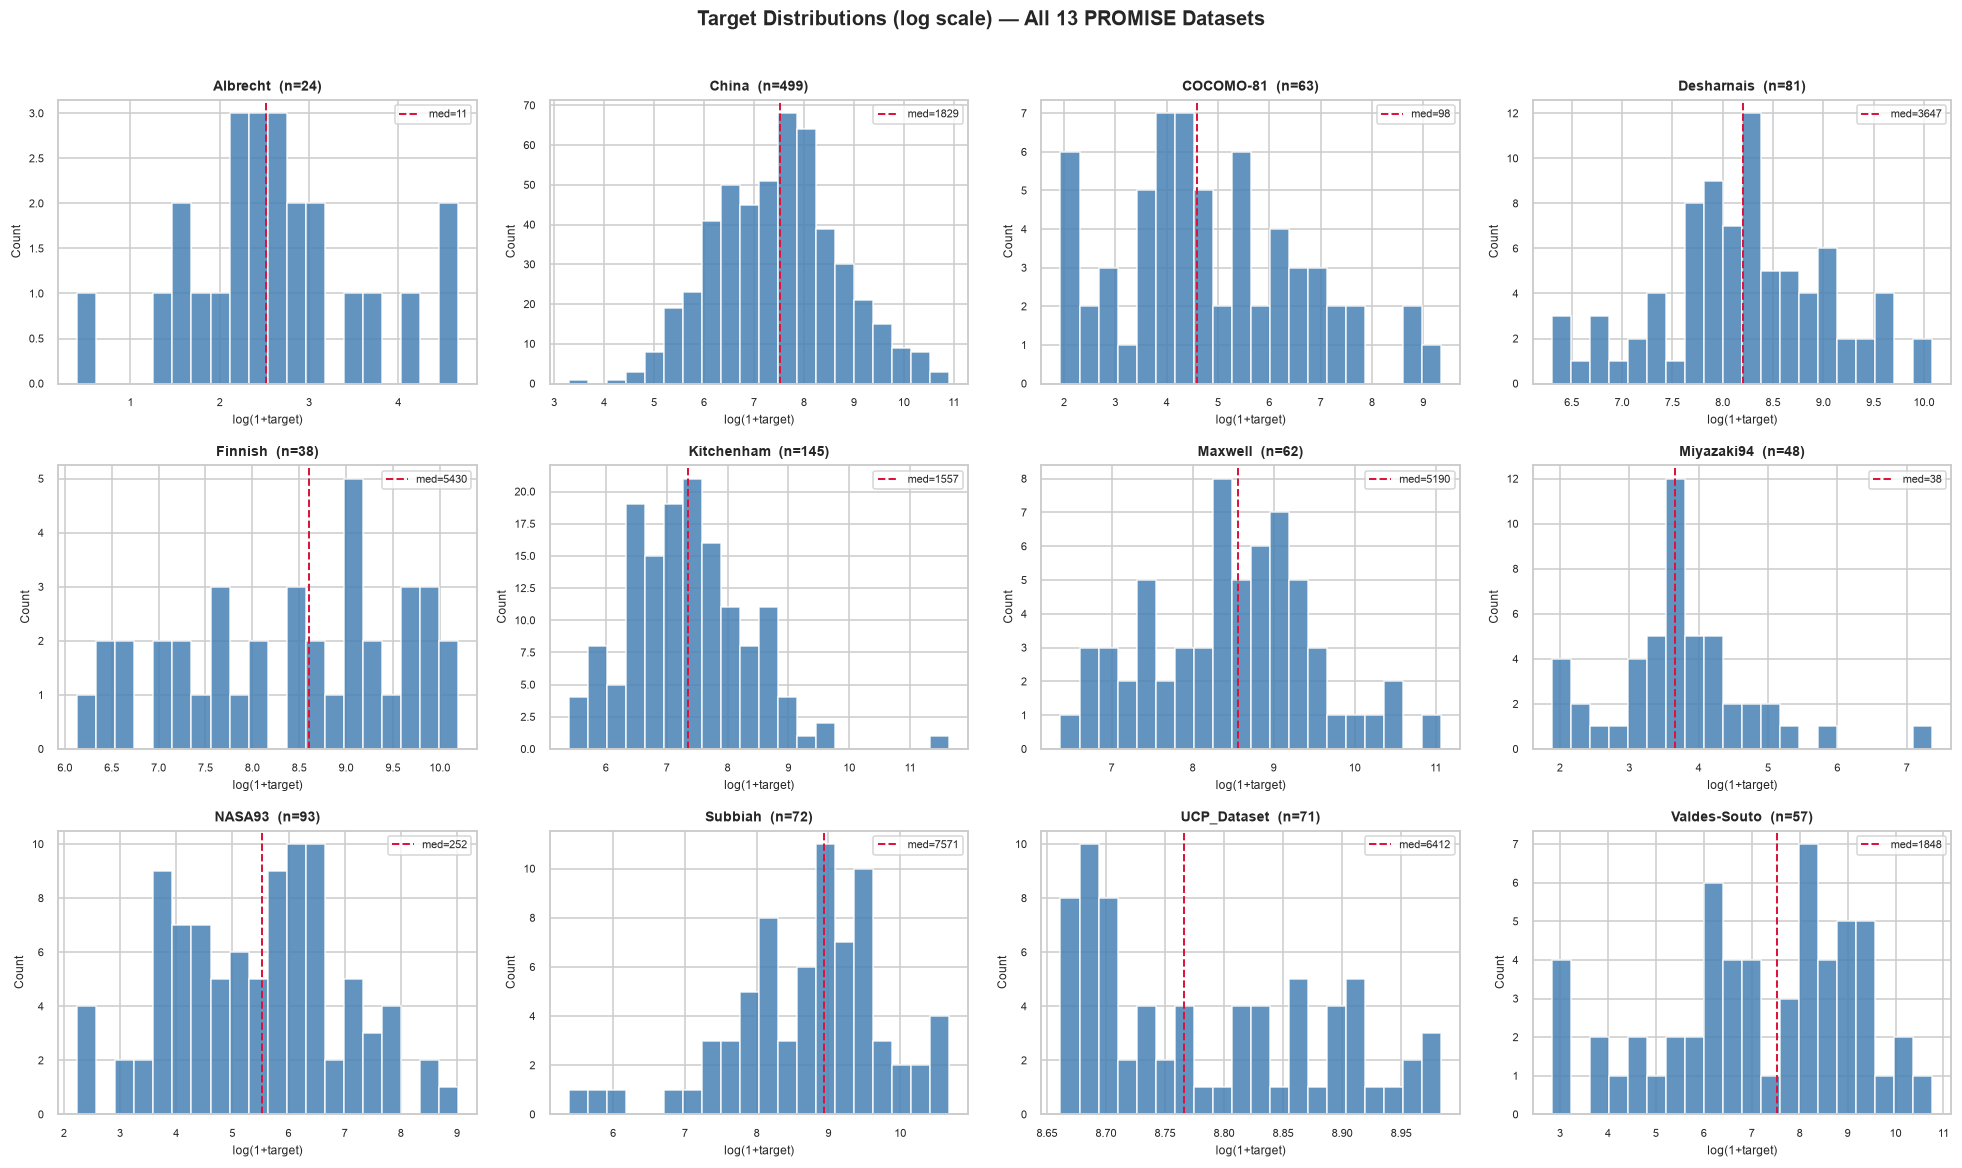

Saved: target_distributions.png


In [5]:
# ── Target histograms ─────────────────────────────────────────────
ncols = 4
nrows = (len(all_datasets) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 3.5))
axes = axes.flatten()

for i, (name, m) in enumerate(all_datasets.items()):
    y   = m['df'][m['target']].dropna()
    ax  = axes[i]
    ax.hist(np.log1p(y), bins=20, color='steelblue', edgecolor='white', alpha=0.85)
    ax.axvline(np.log1p(y.median()), color='crimson', lw=1.3, ls='--',
               label=f'med={y.median():.0f}')
    ax.set_title(f'{name}  (n={len(y)})', fontsize=9, fontweight='bold')
    ax.set_xlabel(f'log(1+target)', fontsize=8)
    ax.set_ylabel('Count', fontsize=8)
    ax.tick_params(labelsize=7); ax.legend(fontsize=7)

for j in range(i+1, len(axes)): axes[j].set_visible(False)
plt.suptitle('Target Distributions (log scale) — All 13 PROMISE Datasets',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('target_distributions.png', bbox_inches='tight', dpi=110)
plt.show(); print('Saved: target_distributions.png')

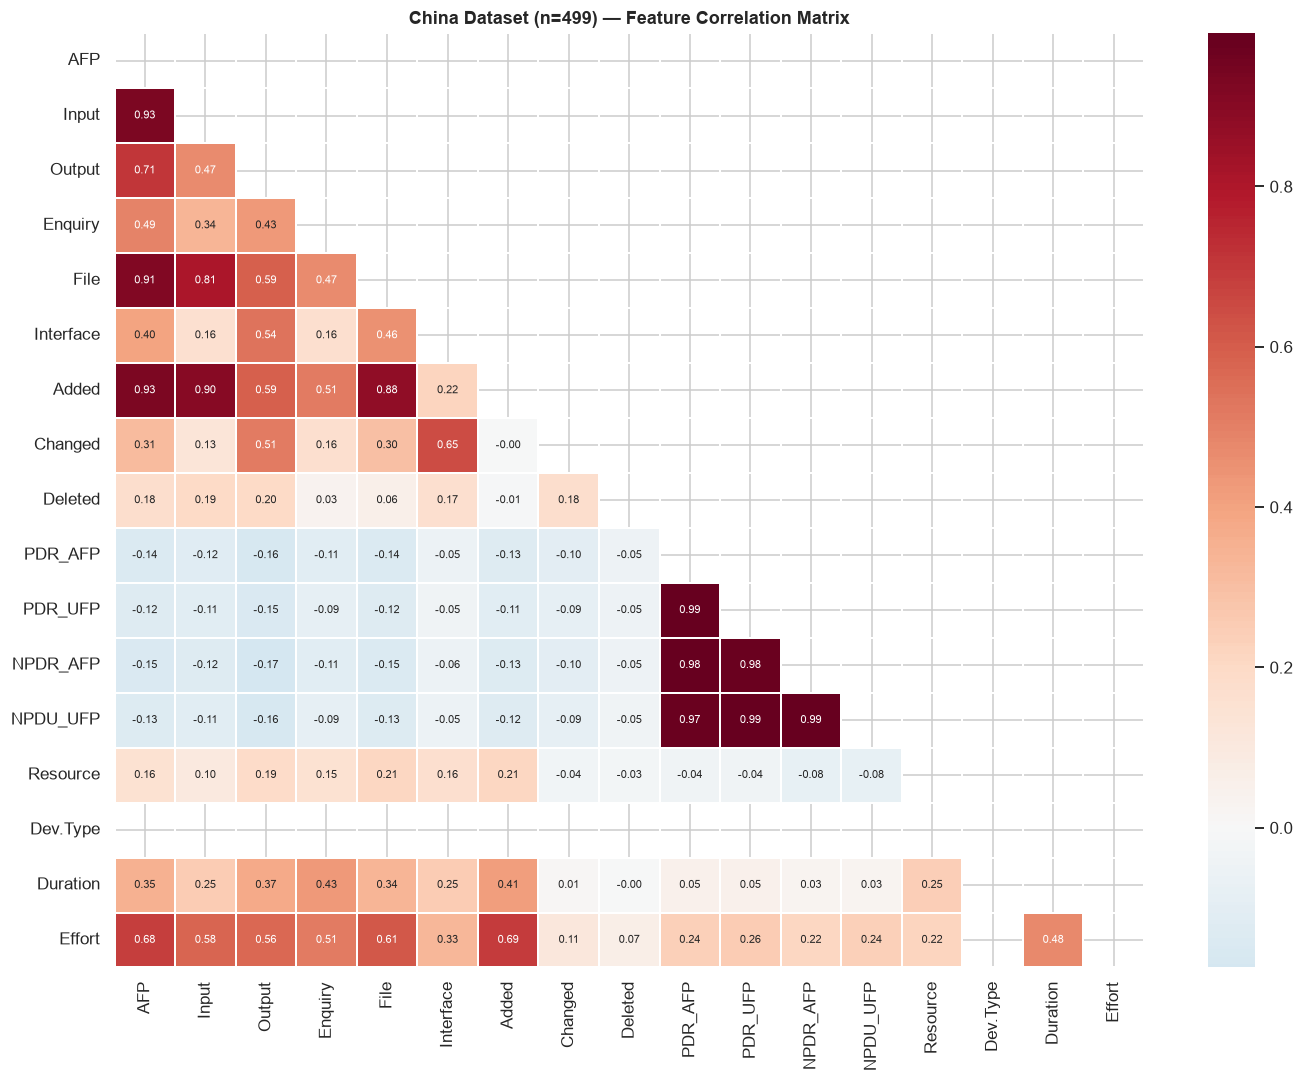

In [6]:
# ── Correlation heatmap — China (largest dataset) ─────────────────
if 'China' in all_datasets:
    num_df = all_datasets['China']['df'].select_dtypes(include=[np.number])
    fig, ax = plt.subplots(figsize=(13, 10))
    mask = np.triu(np.ones_like(num_df.corr(), dtype=bool))
    sns.heatmap(num_df.corr(), mask=mask, annot=True, fmt='.2f',
                cmap='RdBu_r', center=0, ax=ax, annot_kws={'size': 7}, linewidths=0.3)
    ax.set_title('China Dataset (n=499) — Feature Correlation Matrix', fontweight='bold')
    plt.tight_layout()
    plt.savefig('corr_china.png', bbox_inches='tight', dpi=100)
    plt.show()

In [7]:
# ── Missing value report ──────────────────────────────────────────
print('=== Missing Value Report ===')
for name, m in all_datasets.items():
    miss = m['df'].isnull().sum()
    miss = miss[miss > 0]
    if len(miss):
        print(f'\n{name}:')
        for col, cnt in miss.items():
            print(f'  {col}: {cnt} ({cnt/len(m["df"])*100:.1f}%)')
    else:
        print(f'{name}: no missing values')

=== Missing Value Report ===
Albrecht: no missing values
China: no missing values
COCOMO-81: no missing values
Desharnais: no missing values
Finnish: no missing values

Kitchenham:
  Project.type: 10 (6.9%)
Maxwell: no missing values
Miyazaki94: no missing values

NASA93:
  rely: 93 (100.0%)
  data: 93 (100.0%)
  cplx: 93 (100.0%)
  time: 93 (100.0%)
  stor: 93 (100.0%)
  virt: 93 (100.0%)
  turn: 93 (100.0%)
  acap: 93 (100.0%)
  aexp: 93 (100.0%)
  pcap: 93 (100.0%)
  vexp: 93 (100.0%)
  lexp: 93 (100.0%)
  modp: 93 (100.0%)
  tool: 93 (100.0%)
  sced: 93 (100.0%)

Subbiah:
  HoursToCount: 21 (29.2%)

UCP_Dataset:
  Simple Actors: 1 (1.4%)
  Sector: 71 (100.0%)
  Language: 71 (100.0%)
  Methodology: 71 (100.0%)
  ApplicationType: 71 (100.0%)

Valdes-Souto:
  BASE: 57 (100.0%)


## 4. SE Evaluation Metrics

In [8]:
def mmre(yt, yp):
    """Mean Magnitude of Relative Error."""
    return float(np.mean(np.abs(yt - yp) / np.maximum(np.abs(yt), 1e-9)))

def mdmre(yt, yp):
    """Median MRE."""
    return float(np.median(np.abs(yt - yp) / np.maximum(np.abs(yt), 1e-9)))

def pred_n(yt, yp, t=0.25):
    """PRED(n): fraction within t*100% of actual."""
    return float(np.mean(np.abs(yt - yp) / np.maximum(np.abs(yt), 1e-9) <= t))

def signed_bias(yt, yp):
    """Signed mean relative error."""
    return float(np.mean((yp - yt) / np.maximum(np.abs(yt), 1e-9)))

def all_metrics(yt, yp):
    yt  = np.asarray(yt, dtype=float)
    yp  = np.maximum(np.asarray(yp, dtype=float), 0.0)
    return {
        'n_test' : len(yt),
        'MAE'    : round(mean_absolute_error(yt, yp), 2),
        'RMSE'   : round(np.sqrt(mean_squared_error(yt, yp)), 2),
        'MMRE'   : round(mmre(yt, yp), 4),
        'MdMRE'  : round(mdmre(yt, yp), 4),
        'PRED25' : round(pred_n(yt, yp, 0.25), 4),
        'PRED50' : round(pred_n(yt, yp, 0.50), 4),
        'Bias'   : round(signed_bias(yt, yp), 4),
    }

GATE = {'min_PRED25': 0.30}
MIN_ROWS_APPROVE = 25
print('Metrics: MMRE, MdMRE, PRED25, PRED50, Bias, MAE, RMSE')
print(f'Approval gate: PRED25 >= {GATE["min_PRED25"]:.0%} AND MAE < baseline AND n >= {MIN_ROWS_APPROVE}')

Metrics: MMRE, MdMRE, PRED25, PRED50, Bias, MAE, RMSE
Approval gate: PRED25 >= 30% AND MAE < baseline AND n >= 25


## 5. Preprocessing Pipeline

In [9]:
def build_preprocessor(X: pd.DataFrame):
    """ColumnTransformer: median-impute + scale numeric; mode-impute + OHE categorical."""
    num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()
    transformers = []
    if num_cols:
        transformers.append(('num', Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('sc',  StandardScaler())
        ]), num_cols))
    if cat_cols:
        transformers.append(('cat', Pipeline([
            ('imp', SimpleImputer(strategy='most_frequent')),
            ('enc', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), cat_cols))
    return ColumnTransformer(transformers, remainder='drop'), num_cols, cat_cols


def holdout_split(df, frac=0.20, seed=RANDOM_SEED):
    idx = np.arange(len(df))
    np.random.RandomState(seed).shuffle(idx)
    cut = int(len(df) * (1 - frac))
    return df.iloc[idx[:cut]].copy(), df.iloc[idx[cut:]].copy()

print('Preprocessing pipeline utility ready.')

Preprocessing pipeline utility ready.


## 6. Model Candidates

In [10]:
class MedianBaseline:
    """Predicts training-set median — the benchmark every ML model must beat."""
    def fit(self, X, y):  self.median_ = float(np.median(y)); return self
    def predict(self, X): return np.full(len(X), self.median_)

class ABE:
    """Analogy-Based Estimation (k-NN in scaled feature space)."""
    def __init__(self, k=3): self.k = k
    def fit(self, X, y):     self.nn_ = KNeighborsRegressor(n_neighbors=self.k).fit(X, y); return self
    def predict(self, X):    return self.nn_.predict(X)


def get_candidates(seed=RANDOM_SEED):
    c = {
        'Median_Baseline' : MedianBaseline(),
        'ABE_k3'          : ABE(k=3),
        'Ridge'           : Ridge(alpha=10.0),
        'HuberRegressor'  : HuberRegressor(epsilon=1.35, max_iter=500),
        'RandomForest'    : RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                                   random_state=seed, n_jobs=-1),
        'GradBoost'       : GradientBoostingRegressor(n_estimators=200, max_depth=4,
                                                       learning_rate=0.05, subsample=0.8,
                                                       random_state=seed),
        'DecisionTree'    : DecisionTreeRegressor(max_depth=6, min_samples_leaf=3,
                                                   random_state=seed),
    }
    if XGB_AVAILABLE:
        c['XGBoost'] = xgb.XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.05,
                                          subsample=0.8, colsample_bytree=0.8,
                                          random_state=seed, verbosity=0)
    return c

print('Candidates:', list(get_candidates().keys()))

Candidates: ['Median_Baseline', 'ABE_k3', 'Ridge', 'HuberRegressor', 'RandomForest', 'GradBoost', 'DecisionTree', 'XGBoost']


## 7. Training & Evaluation — All 13 Datasets

**Protocol:** 80/20 random holdout split (seed=42). Preprocessor fitted on train fold only.  
All candidates trained on the same train fold; metrics on the same held-out test fold.  
Log₁₊ transform applied to the target (standard for right-skewed effort data).

In [11]:
all_results = {}   # {ds_name: [result_dict, ...]}

for ds_name, meta in all_datasets.items():
    df  = meta['df'].copy()
    tgt = meta['target']
    n   = len(df)

    print(f"\n{'='*65}")
    print(f"  {ds_name}  —  n={n}  target={tgt}")
    print(f"{'='*65}")

    if n < 10:
        print(f'  SKIPPED — only {n} usable rows.')
        continue

    frac = 0.20 if n >= 30 else 0.30
    df_tr, df_te = holdout_split(df, frac=frac)
    print(f'  Train={len(df_tr)}  Test={len(df_te)}  (frac={frac:.0%})')
    if len(df_te) < 3:
        print('  SKIPPED — test set too small.');
        continue

    y_tr  = df_tr[tgt].values
    y_te  = df_te[tgt].values
    y_tr_log = np.log1p(y_tr)

    X_tr_df = df_tr.drop(columns=[tgt])
    X_te_df = df_te.drop(columns=[tgt])
    prep, num_cols, cat_cols = build_preprocessor(X_tr_df)
    X_tr = prep.fit_transform(X_tr_df)
    X_te = prep.transform(X_te_df)

    # ── Baseline ──────────────────────────────────────────────────
    bl = MedianBaseline().fit(X_tr, y_tr)
    bl_m = all_metrics(y_te, bl.predict(X_te))
    print(f'  Baseline   MAE={bl_m["MAE"]:>10.1f}  MMRE={bl_m["MMRE"]:.3f}  PRED25={bl_m["PRED25"]:.3f}')
    ds_res = [{'model': 'Median_Baseline', 'status': 'BASELINE', 'reason': '', **bl_m}]

    small = (n < MIN_ROWS_APPROVE)

    # ── ML candidates ─────────────────────────────────────────────
    for mname, model in {k: v for k, v in get_candidates().items()
                         if k != 'Median_Baseline'}.items():
        try:
            if isinstance(model, ABE):
                model.fit(X_tr, y_tr)
                yp = model.predict(X_te)
            else:
                model.fit(X_tr, y_tr_log)
                yp = np.expm1(model.predict(X_te))
            yp = np.maximum(yp, 0.0)
            m  = all_metrics(y_te, yp)

            if small:
                status = 'EXPERIMENTAL'
                reason = f'n={n} < {MIN_ROWS_APPROVE} (too small for APPROVED)'
            elif m['MAE'] < bl_m['MAE'] and m['PRED25'] >= GATE['min_PRED25']:
                status = 'APPROVED'; reason = ''
            else:
                status = 'REJECTED'
                parts  = []
                if m['MAE'] >= bl_m['MAE']:
                    parts.append(f'MAE {m["MAE"]:.1f} >= baseline {bl_m["MAE"]:.1f}')
                if m['PRED25'] < GATE['min_PRED25']:
                    parts.append(f'PRED25 {m["PRED25"]:.3f} < gate {GATE["min_PRED25"]}')
                reason = '; '.join(parts)

            icon = {'APPROVED': '✓', 'EXPERIMENTAL': '~', 'REJECTED': '✗'}[status]
            print(f'  {icon} {mname:20s}  MAE={m["MAE"]:>10.1f}  '
                  f'MMRE={m["MMRE"]:.3f}  PRED25={m["PRED25"]:.3f}  [{status}]'
                  + (f'  ({reason})' if reason else ''))
            ds_res.append({'model': mname, 'status': status, 'reason': reason, **m})

        except Exception as exc:
            print(f'  ✗ {mname}: ERROR — {exc}')
            ds_res.append({'model': mname, 'status': 'ERROR', 'reason': str(exc)})

    all_results[ds_name] = ds_res

print('\n\n=== Training & Evaluation Complete ===')


  Albrecht  —  n=24  target=Effort
  Train=16  Test=8  (frac=30%)
  Baseline   MAE=      12.6  MMRE=1.408  PRED25=0.000
  ~ ABE_k3                MAE=       8.0  MMRE=0.760  PRED25=0.250  [EXPERIMENTAL]  (n=24 < 25 (too small for APPROVED))
  ~ Ridge                 MAE=       2.6  MMRE=0.405  PRED25=0.500  [EXPERIMENTAL]  (n=24 < 25 (too small for APPROVED))
  ~ HuberRegressor        MAE=       6.4  MMRE=0.439  PRED25=0.375  [EXPERIMENTAL]  (n=24 < 25 (too small for APPROVED))


  ~ RandomForest          MAE=       3.6  MMRE=0.534  PRED25=0.625  [EXPERIMENTAL]  (n=24 < 25 (too small for APPROVED))
  ~ GradBoost             MAE=       5.6  MMRE=0.852  PRED25=0.375  [EXPERIMENTAL]  (n=24 < 25 (too small for APPROVED))
  ~ DecisionTree          MAE=       6.5  MMRE=0.929  PRED25=0.375  [EXPERIMENTAL]  (n=24 < 25 (too small for APPROVED))


  ~ XGBoost               MAE=       6.8  MMRE=0.894  PRED25=0.125  [EXPERIMENTAL]  (n=24 < 25 (too small for APPROVED))

  China  —  n=499  target=Effort
  Train=399  Test=100  (frac=20%)
  Baseline   MAE=    3242.1  MMRE=1.350  PRED25=0.140
  ✓ ABE_k3                MAE=    1537.9  MMRE=0.349  PRED25=0.450  [APPROVED]
  ✗ Ridge                 MAE=    6883.8  MMRE=1.143  PRED25=0.250  [REJECTED]  (MAE 6883.8 >= baseline 3242.1; PRED25 0.250 < gate 0.3)
  ✗ HuberRegressor        MAE=    3929.6  MMRE=0.771  PRED25=0.290  [REJECTED]  (MAE 3929.6 >= baseline 3242.1; PRED25 0.290 < gate 0.3)


  ✓ RandomForest          MAE=     577.1  MMRE=0.109  PRED25=0.930  [APPROVED]


  ✓ GradBoost             MAE=     457.7  MMRE=0.088  PRED25=0.960  [APPROVED]
  ✓ DecisionTree          MAE=    1289.9  MMRE=0.280  PRED25=0.560  [APPROVED]
  ✓ XGBoost               MAE=     453.8  MMRE=0.101  PRED25=0.960  [APPROVED]

  COCOMO-81  —  n=63  target=actual
  Train=50  Test=13  (frac=20%)
  Baseline   MAE=     862.5  MMRE=3.397  PRED25=0.077
  ✗ ABE_k3                MAE=     462.8  MMRE=4.460  PRED25=0.154  [REJECTED]  (PRED25 0.154 < gate 0.3)
  ✗ Ridge                 MAE=   20185.3  MMRE=4.822  PRED25=0.077  [REJECTED]  (MAE 20185.3 >= baseline 862.5; PRED25 0.077 < gate 0.3)
  ✗ HuberRegressor        MAE=  114687.3  MMRE=19.105  PRED25=0.154  [REJECTED]  (MAE 114687.3 >= baseline 862.5; PRED25 0.154 < gate 0.3)


...

  ✗ RandomForest          MAE=    5407.1  MMRE=0.999  PRED25=0.067  [REJECTED]  (MAE 5407.1 >= baseline 5359.3; PRED25 0.067 < gate 0.3)
  ✗ GradBoost             MAE=    4777.7  MMRE=0.818  PRED25=0.267  [REJECTED]  (PRED25 0.267 < gate 0.3)
  ✗ DecisionTree          MAE=    5039.1  MMRE=0.821  PRED25=0.200  [REJECTED]  (PRED25 0.200 < gate 0.3)
  ✗ XGBoost               MAE=    4979.8  MMRE=0.894  PRED25=0.133  [REJECTED]  (PRED25 0.133 < gate 0.3)

  UCP_Dataset  —  n=71  target=Real_Effort_Person_Hours
  Train=56  Test=15  (frac=20%)
  Baseline   MAE=     626.2  MMRE=0.092  PRED25=1.000
  ✓ ABE_k3                MAE=     376.9  MMRE=0.055  PRED25=1.000  [APPROVED]
  ✓ Ridge                 MAE=     517.6  MMRE=0.078  PRED25=1.000  [APPROVED]
  ✓ HuberRegressor        MAE=     510.8  MMRE=0.077  PRED25=1.000  [APPROVED]


  ✓ RandomForest          MAE=     247.7  MMRE=0.036  PRED25=1.000  [APPROVED]
  ✓ GradBoost             MAE=     179.8  MMRE=0.025  PRED25=1.000  [APPROVED]
  ✓ DecisionTree          MAE=     187.5  MMRE=0.027  PRED25=1.000  [APPROVED]


  ✓ XGBoost               MAE=     200.3  MMRE=0.029  PRED25=1.000  [APPROVED]

  Valdes-Souto  —  n=57  target=Effort
  Train=45  Test=12  (frac=20%)
  Baseline   MAE=    3144.7  MMRE=22.021  PRED25=0.083
  ✓ ABE_k3                MAE=     954.4  MMRE=6.940  PRED25=0.417  [APPROVED]
  ✗ Ridge                 MAE=    2508.7  MMRE=5.962  PRED25=0.250  [REJECTED]  (PRED25 0.250 < gate 0.3)
  ✗ HuberRegressor        MAE=    2359.1  MMRE=6.251  PRED25=0.167  [REJECTED]  (PRED25 0.167 < gate 0.3)


  ✗ RandomForest          MAE=    1182.6  MMRE=6.282  PRED25=0.250  [REJECTED]  (PRED25 0.250 < gate 0.3)
  ✓ GradBoost             MAE=    1236.1  MMRE=11.130  PRED25=0.333  [APPROVED]
  ✓ DecisionTree          MAE=    1138.9  MMRE=8.074  PRED25=0.333  [APPROVED]


  ✓ XGBoost               MAE=     838.2  MMRE=9.524  PRED25=0.500  [APPROVED]


=== Training & Evaluation Complete ===


## 8. Results Tables

In [12]:
result_rows = []
for ds, res in all_results.items():
    for r in res: result_rows.append({'Dataset': ds, **r})
results_df = pd.DataFrame(result_rows)
valid_df   = results_df.dropna(subset=['MAE'])

show_cols = ['Dataset','model','status','n_test','MAE','RMSE','MMRE','MdMRE','PRED25','PRED50','Bias']
show_cols = [c for c in show_cols if c in valid_df.columns]
pd.set_option('display.max_rows', 200)
print('=== Full Results ===')
print(valid_df[show_cols].to_string(index=False))

=== Full Results ===
     Dataset           model       status  n_test       MAE      RMSE    MMRE  MdMRE  PRED25  PRED50    Bias
    Albrecht Median_Baseline     BASELINE       8     12.61     18.22  1.4084 1.0731  0.0000  0.1250  1.2171
    Albrecht          ABE_k3 EXPERIMENTAL       8      7.98     13.33  0.7603 0.6389  0.2500  0.3750  0.6127
    Albrecht           Ridge EXPERIMENTAL       8      2.64      3.45  0.4046 0.2046  0.5000  0.8750  0.2524
    Albrecht  HuberRegressor EXPERIMENTAL       8      6.37     13.19  0.4388 0.2526  0.3750  0.7500  0.2801
    Albrecht    RandomForest EXPERIMENTAL       8      3.63      5.13  0.5341 0.1846  0.6250  0.7500  0.2746
    Albrecht       GradBoost EXPERIMENTAL       8      5.59      7.51  0.8524 0.4272  0.3750  0.6250  0.3871
    Albrecht    DecisionTree EXPERIMENTAL       8      6.50      8.57  0.9295 0.4458  0.3750  0.5000  0.4939
    Albrecht         XGBoost EXPERIMENTAL       8      6.85      8.99  0.8942 0.6699  0.1250  0.3750  0.170

In [13]:
best = (valid_df
        .loc[valid_df.groupby('Dataset')['MAE'].idxmin()]
        [['Dataset','model','status','MAE','MMRE','PRED25','Bias']]
        .sort_values('PRED25', ascending=False))
print('\n=== Best Model Per Dataset (by held-out MAE) ===')
print(best.to_string(index=False))


=== Best Model Per Dataset (by held-out MAE) ===
     Dataset        model       status     MAE   MMRE  PRED25    Bias
 UCP_Dataset    GradBoost     APPROVED  179.81 0.0254  1.0000 -0.0097
       China      XGBoost     APPROVED  453.77 0.1006  0.9600  0.0147
  Kitchenham RandomForest     APPROVED  411.50 0.2138  0.8276  0.0656
     Finnish    GradBoost     APPROVED 1088.79 0.4350  0.7500  0.1668
     Maxwell    GradBoost     APPROVED 2640.59 0.2672  0.6923  0.0410
  Miyazaki94 RandomForest     APPROVED   21.06 0.2783  0.5000 -0.0932
    Albrecht        Ridge EXPERIMENTAL    2.64 0.4046  0.5000  0.2524
Valdes-Souto      XGBoost     APPROVED  838.18 9.5237  0.5000  9.2948
      NASA93 DecisionTree     APPROVED  167.29 0.3988  0.4737  0.0585
  Desharnais      XGBoost     APPROVED 2138.00 0.4610  0.3529  0.1511
     Subbiah    GradBoost     REJECTED 4777.67 0.8178  0.2667  0.3527
   COCOMO-81       ABE_k3     REJECTED  462.75 4.4604  0.1538  3.9834


## 9. Visualisations

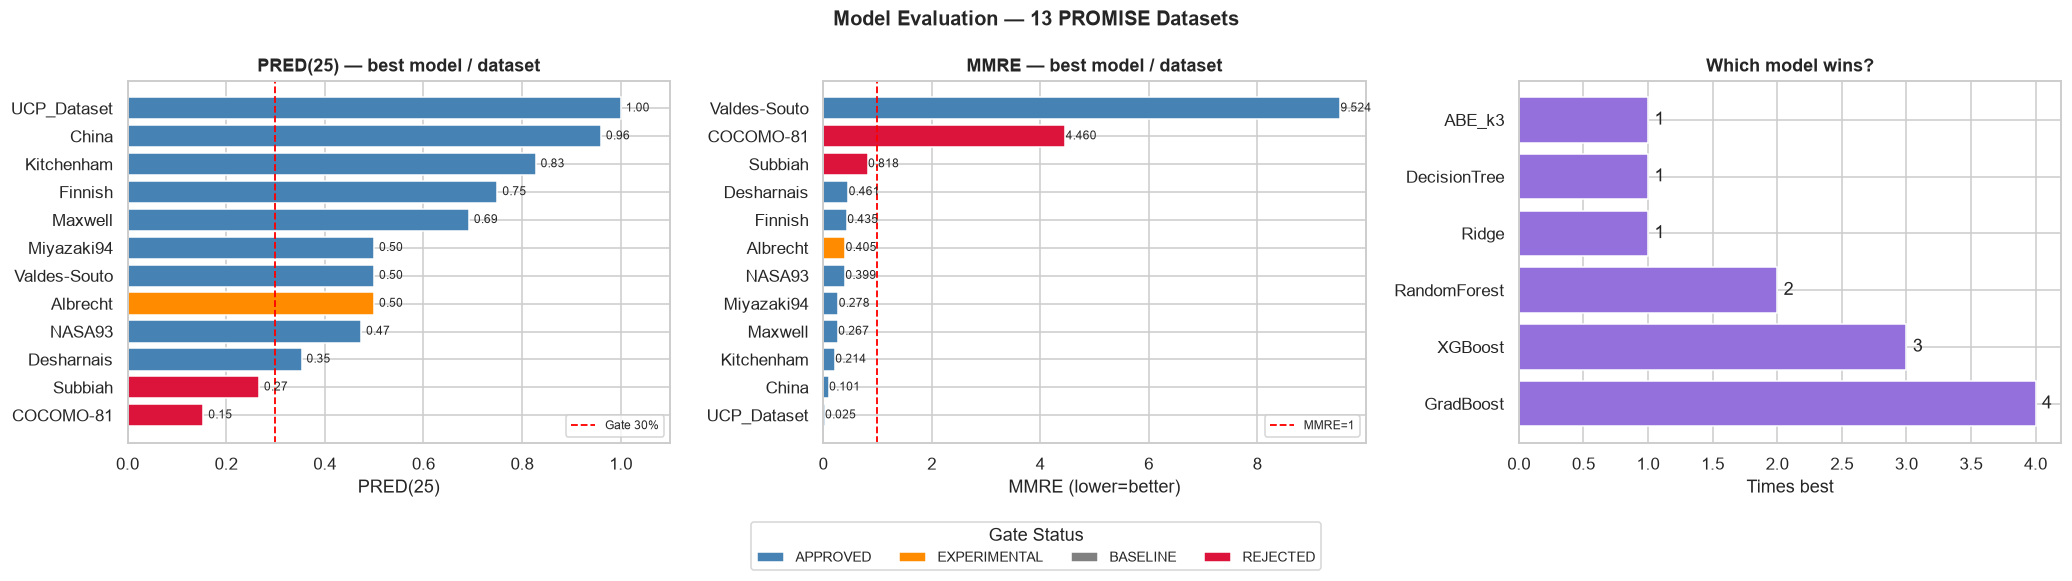

Saved: model_comparison_summary.png


In [14]:
# ── Metric summary charts ─────────────────────────────────────────
SC = {'APPROVED':'steelblue','EXPERIMENTAL':'darkorange','BASELINE':'grey','REJECTED':'crimson'}

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# PRED25
d = best.sort_values('PRED25', ascending=True)
bc = [SC.get(s,'grey') for s in d['status']]
bars = axes[0].barh(d['Dataset'], d['PRED25'], color=bc)
axes[0].axvline(GATE['min_PRED25'], color='red', ls='--', lw=1.2, label=f"Gate {GATE['min_PRED25']:.0%}")
axes[0].set_xlim(0, 1.1); axes[0].set_xlabel('PRED(25)')
axes[0].set_title('PRED(25) — best model / dataset', fontweight='bold'); axes[0].legend(fontsize=8)
for bar, v in zip(bars, d['PRED25']):
    axes[0].text(v+.01, bar.get_y()+bar.get_height()/2, f'{v:.2f}', va='center', fontsize=8)

# MMRE
d2 = best.sort_values('MMRE')
bc2 = [SC.get(s,'grey') for s in d2['status']]
bars2 = axes[1].barh(d2['Dataset'], d2['MMRE'], color=bc2)
axes[1].axvline(1.0, color='red', ls='--', lw=1.2, label='MMRE=1')
axes[1].set_xlabel('MMRE (lower=better)')
axes[1].set_title('MMRE — best model / dataset', fontweight='bold'); axes[1].legend(fontsize=8)
for bar, v in zip(bars2, d2['MMRE']):
    axes[1].text(v+.01, bar.get_y()+bar.get_height()/2, f'{v:.3f}', va='center', fontsize=8)

# Win count
mc = best['model'].value_counts()
axes[2].barh(mc.index, mc.values, color='mediumpurple')
axes[2].set_xlabel('Times best'); axes[2].set_title('Which model wins?', fontweight='bold')
for i, v in enumerate(mc.values): axes[2].text(v+.05, i, str(v), va='center')

fig.legend(handles=[Patch(facecolor=c, label=s) for s,c in SC.items()],
           loc='lower center', ncol=4, fontsize=9, title='Gate Status',
           bbox_to_anchor=(0.5,-0.05))
plt.suptitle('Model Evaluation — 13 PROMISE Datasets', fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0,0.06,1,1])
plt.savefig('model_comparison_summary.png', bbox_inches='tight', dpi=120)
plt.show(); print('Saved: model_comparison_summary.png')

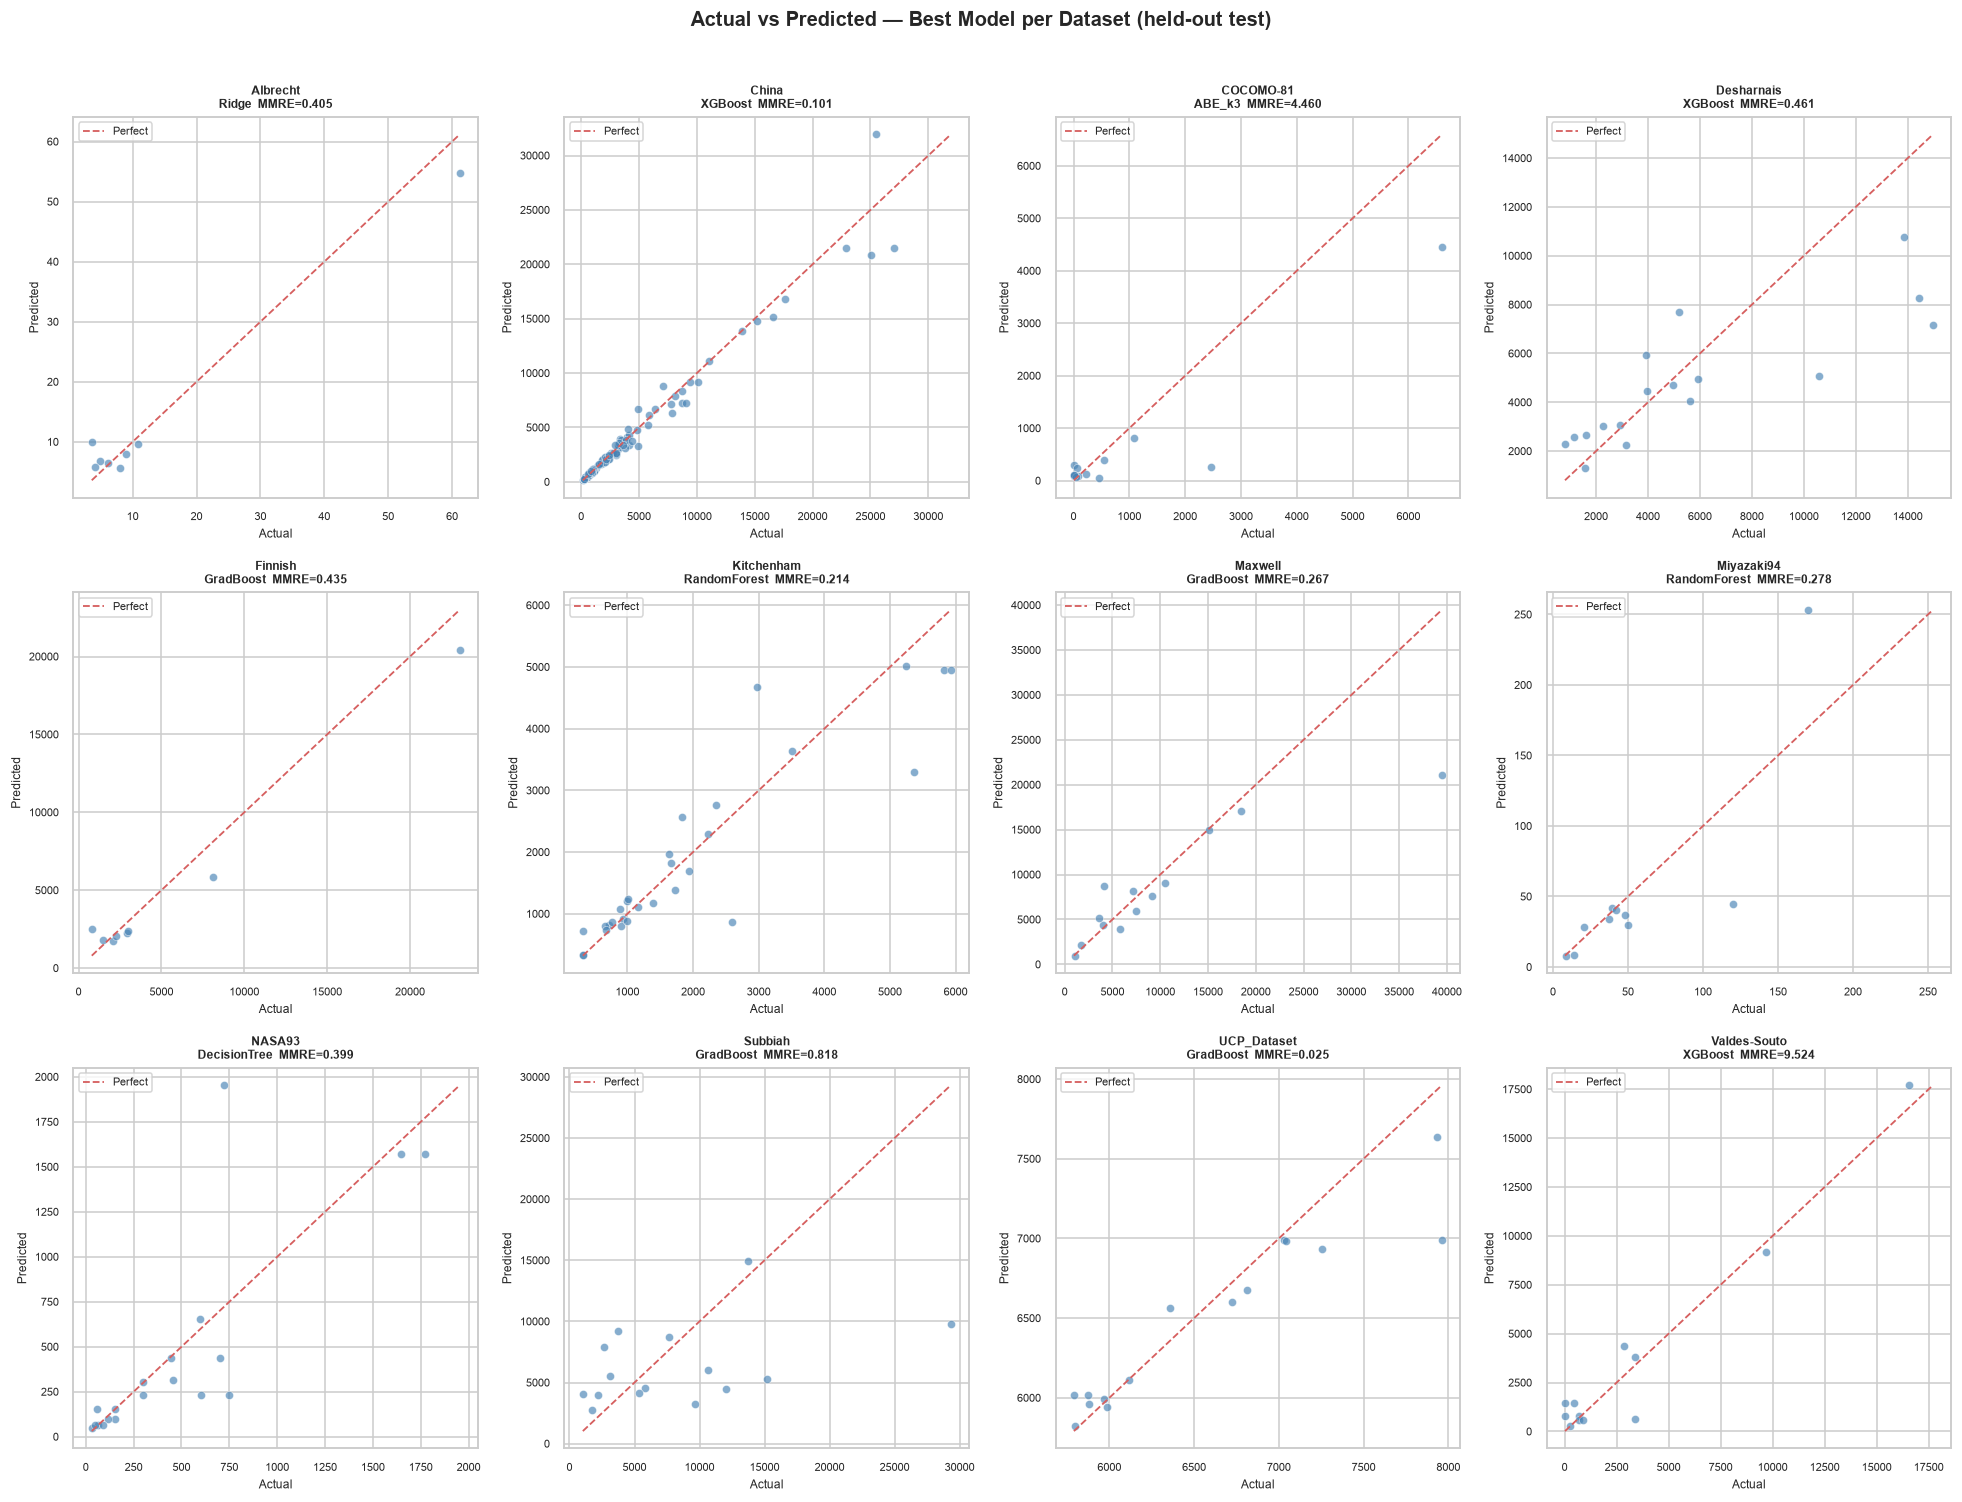

Saved: actual_vs_predicted.png


In [15]:
# ── Actual vs Predicted scatter ───────────────────────────────────
ncols = 4
nrows = (len(all_datasets)+ncols-1)//ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows*4.5))
axes = axes.flatten(); pi = 0

for ds_name, meta in all_datasets.items():
    df  = meta['df'].copy(); tgt = meta['target']; n = len(df)
    if n < 10: continue
    frac = 0.20 if n >= 30 else 0.30
    df_tr, df_te = holdout_split(df, frac=frac)
    y_te  = df_te[tgt].values
    X_tr_df = df_tr.drop(columns=[tgt]); X_te_df = df_te.drop(columns=[tgt])
    prep, _, _ = build_preprocessor(X_tr_df)
    X_tr = prep.fit_transform(X_tr_df); X_te = prep.transform(X_te_df)
    y_tr_log = np.log1p(df_tr[tgt].values)

    ax = axes[pi]; pi += 1
    non_bl = [r for r in all_results.get(ds_name,[]) if r['model']!='Median_Baseline' and r.get('MAE')]

    if non_bl:
        best_m = min(non_bl, key=lambda r: r['MAE'])['model']
        model  = get_candidates().get(best_m)
        if model is not None:
            try:
                if isinstance(model, ABE):
                    model.fit(X_tr, df_tr[tgt].values); yp = model.predict(X_te)
                else:
                    model.fit(X_tr, y_tr_log); yp = np.expm1(model.predict(X_te))
                yp = np.maximum(yp, 0)
                lo,hi = min(y_te.min(),yp.min()), max(y_te.max(),yp.max())
                ax.scatter(y_te, yp, alpha=0.65, s=28, color='steelblue', edgecolor='white', lw=0.4)
                ax.plot([lo,hi],[lo,hi],'r--',lw=1.2,label='Perfect')
                ax.set_title(f'{ds_name}\n{best_m}  MMRE={mmre(y_te,yp):.3f}',
                             fontsize=8, fontweight='bold')
                ax.legend(fontsize=7)
            except Exception as e:
                ax.set_title(f'{ds_name}\nErr: {e}', fontsize=7)
        else:
            ax.set_title(f'{ds_name} (model N/A)', fontsize=8)
    else:
        bl2 = MedianBaseline().fit(X_tr, df_tr[tgt].values)
        yp  = bl2.predict(X_te)
        lo,hi = min(y_te.min(),yp.min()), max(y_te.max(),yp.max())
        ax.scatter(y_te, yp, alpha=0.65, s=28, color='grey')
        ax.plot([lo,hi],[lo,hi],'r--',lw=1.2)
        ax.set_title(f'{ds_name}\nMedian Baseline', fontsize=8)

    ax.set_xlabel('Actual',fontsize=8); ax.set_ylabel('Predicted',fontsize=8)
    ax.tick_params(labelsize=7)

for j in range(pi,len(axes)): axes[j].set_visible(False)
plt.suptitle('Actual vs Predicted — Best Model per Dataset (held-out test)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('actual_vs_predicted.png', bbox_inches='tight', dpi=110)
plt.show(); print('Saved: actual_vs_predicted.png')

## 10. 5-Fold Cross-Validation (datasets ≥ 50 rows)

In [16]:
CV_MODELS = ['Ridge','RandomForest','GradBoost'] + (['XGBoost'] if XGB_AVAILABLE else [])
cv_records = []

for ds_name, meta in all_datasets.items():
    df = meta['df'].copy(); tgt = meta['target']
    if len(df) < 50: continue
    print(f'\n{ds_name} (n={len(df)}) — 5-fold CV')
    prep, _, _ = build_preprocessor(df.drop(columns=[tgt]))
    X     = prep.fit_transform(df.drop(columns=[tgt]))
    y_log = np.log1p(df[tgt].values)
    y_raw = df[tgt].values
    kf    = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

    for mname in CV_MODELS:
        fold_scores = []
        for tr_i, va_i in kf.split(X):
            m = get_candidates()[mname]
            m.fit(X[tr_i], y_log[tr_i])
            yp = np.maximum(np.expm1(m.predict(X[va_i])), 0)
            fold_scores.append({'MMRE': mmre(y_raw[va_i],yp),
                                'PRED25': pred_n(y_raw[va_i],yp,0.25),
                                'MAE': mean_absolute_error(y_raw[va_i],yp)})
        fs = pd.DataFrame(fold_scores)
        print(f'  {mname:20s}  MMRE={fs.MMRE.mean():.3f}±{fs.MMRE.std():.3f}  '
              f'PRED25={fs.PRED25.mean():.3f}±{fs.PRED25.std():.3f}  '
              f'MAE={fs.MAE.mean():.1f}±{fs.MAE.std():.1f}')
        cv_records.append({'Dataset':ds_name,'Model':mname,
                           'CV_MMRE':fs.MMRE.mean(),'CV_MMRE_std':fs.MMRE.std(),
                           'CV_PRED25':fs.PRED25.mean(),'CV_MAE':fs.MAE.mean()})

cv_df = pd.DataFrame(cv_records)
print('\nCross-validation complete.')


China (n=499) — 5-fold CV
  Ridge                 MMRE=8.480±12.431  PRED25=0.229±0.036  MAE=361611.1±703820.6


  RandomForest          MMRE=0.161±0.062  PRED25=0.864±0.058  MAE=776.8±348.9


  GradBoost             MMRE=0.120±0.030  PRED25=0.908±0.043  MAE=633.3±251.4


  XGBoost               MMRE=0.123±0.030  PRED25=0.906±0.057  MAE=661.6±266.3

COCOMO-81 (n=63) — 5-fold CV
  Ridge                 MMRE=1.688±1.066  PRED25=0.190±0.070  MAE=1175.5±1677.6


  RandomForest          MMRE=0.744±0.140  PRED25=0.191±0.110  MAE=492.8±439.6


...

  GradBoost             MMRE=0.022±0.002  PRED25=1.000±0.000  MAE=151.0±14.8


  XGBoost               MMRE=0.027±0.004  PRED25=1.000±0.000  MAE=183.1±30.4

Valdes-Souto (n=57) — 5-fold CV
  Ridge                 MMRE=3.630±2.085  PRED25=0.144±0.123  MAE=4237.6±3667.0


  RandomForest          MMRE=2.216±2.753  PRED25=0.330±0.149  MAE=2432.6±1569.1


  GradBoost             MMRE=3.674±4.675  PRED25=0.212±0.081  MAE=3360.0±2108.8


  XGBoost               MMRE=3.909±4.370  PRED25=0.318±0.148  MAE=2918.8±1834.6

Cross-validation complete.


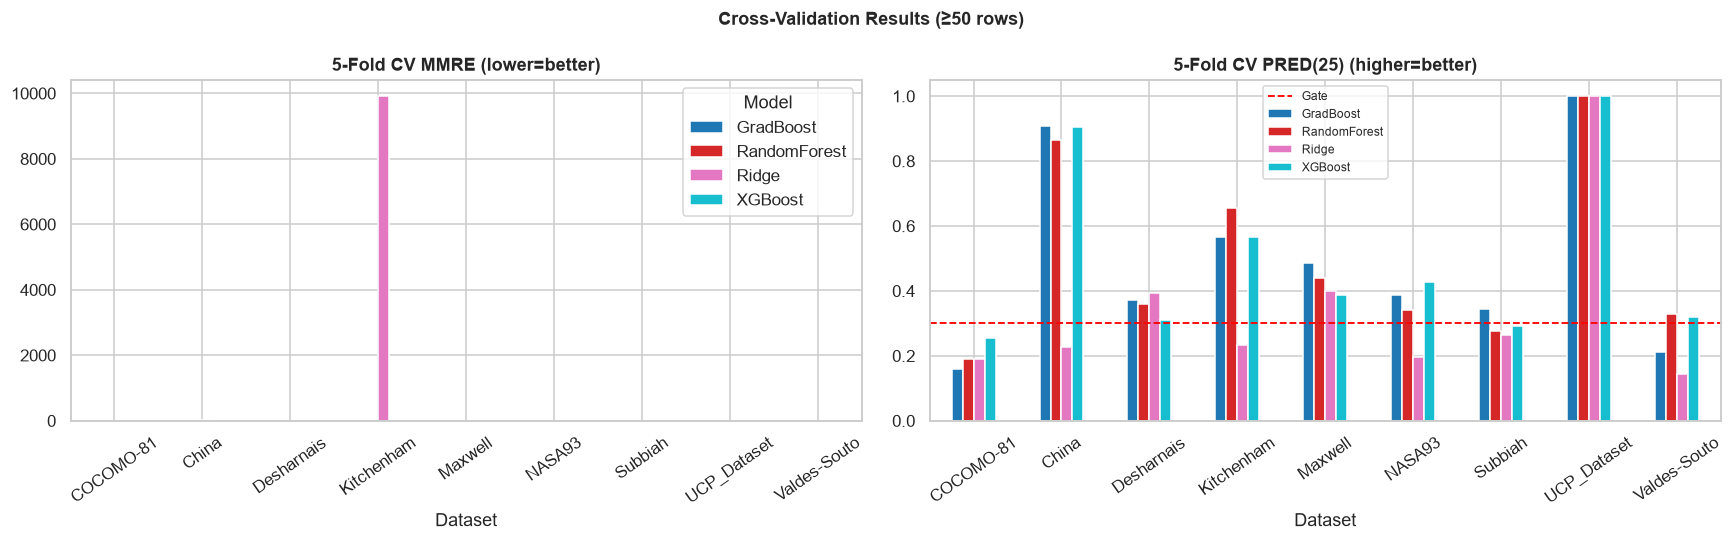

Saved: cv_results.png


In [17]:
if len(cv_df):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    cv_df.pivot(index='Dataset',columns='Model',values='CV_MMRE').plot(
        kind='bar', ax=axes[0], colormap='tab10', edgecolor='white')
    axes[0].set_title('5-Fold CV MMRE (lower=better)', fontweight='bold')
    axes[0].tick_params(axis='x', rotation=35)
    cv_df.pivot(index='Dataset',columns='Model',values='CV_PRED25').plot(
        kind='bar', ax=axes[1], colormap='tab10', edgecolor='white')
    axes[1].axhline(GATE['min_PRED25'], color='red', ls='--', lw=1.2, label='Gate')
    axes[1].set_title('5-Fold CV PRED(25) (higher=better)', fontweight='bold')
    axes[1].tick_params(axis='x', rotation=35); axes[1].legend(fontsize=8)
    plt.suptitle('Cross-Validation Results (≥50 rows)', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('cv_results.png', bbox_inches='tight', dpi=110)
    plt.show(); print('Saved: cv_results.png')

## 11. Feature Importance — Random Forest on China (n=499)

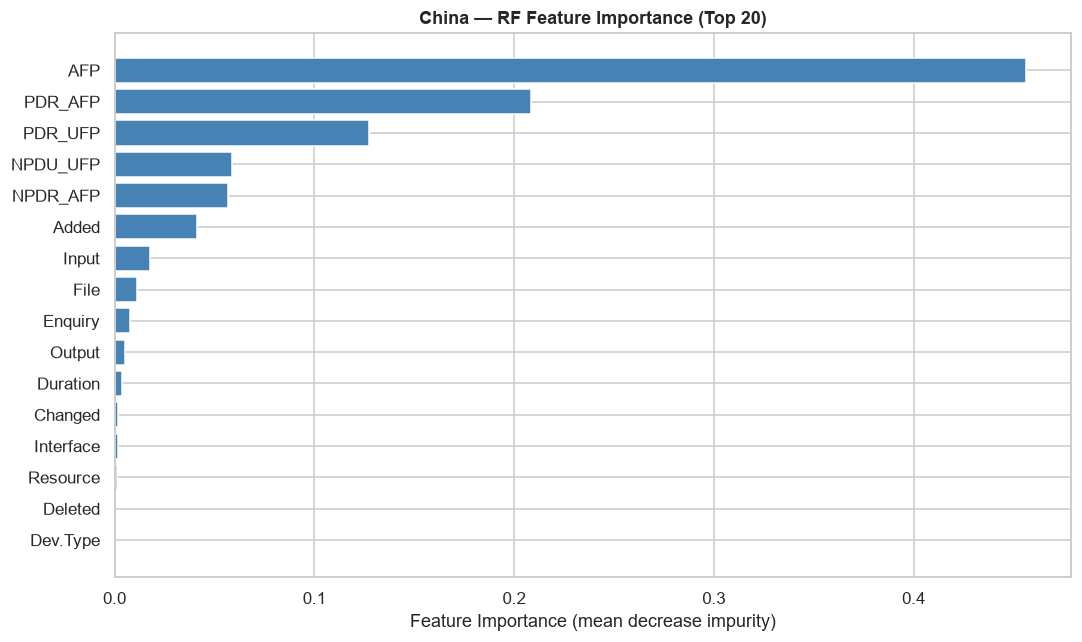

Saved: feature_importance_china.png
 feature  importance
     AFP    0.456202
 PDR_AFP    0.208601
 PDR_UFP    0.127566
NPDU_UFP    0.058642
NPDR_AFP    0.056992
   Added    0.041361
   Input    0.017581
    File    0.011211
 Enquiry    0.007746
  Output    0.005100


In [18]:
if 'China' in all_datasets:
    meta = all_datasets['China']; df = meta['df'].copy(); tgt = meta['target']
    df_tr, df_te = holdout_split(df, frac=0.20)
    X_tr_df = df_tr.drop(columns=[tgt])
    prep, num_cols, cat_cols = build_preprocessor(X_tr_df)
    X_tr = prep.fit_transform(X_tr_df)

    rf = RandomForestRegressor(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1)
    rf.fit(X_tr, np.log1p(df_tr[tgt].values))

    feat_names = list(num_cols)
    if cat_cols and 'cat' in prep.named_transformers_:
        enc = prep.named_transformers_['cat'].named_steps['enc']
        feat_names += list(enc.get_feature_names_out(cat_cols))

    fi = (pd.DataFrame({'feature': feat_names, 'importance': rf.feature_importances_})
          .sort_values('importance', ascending=False).head(20))

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(fi['feature'][::-1], fi['importance'][::-1], color='steelblue')
    ax.set_xlabel('Feature Importance (mean decrease impurity)')
    ax.set_title('China — RF Feature Importance (Top 20)', fontweight='bold')
    plt.tight_layout()
    plt.savefig('feature_importance_china.png', bbox_inches='tight', dpi=110)
    plt.show(); print('Saved: feature_importance_china.png')
    print(fi.head(10).to_string(index=False))

## 12. Residual Analysis

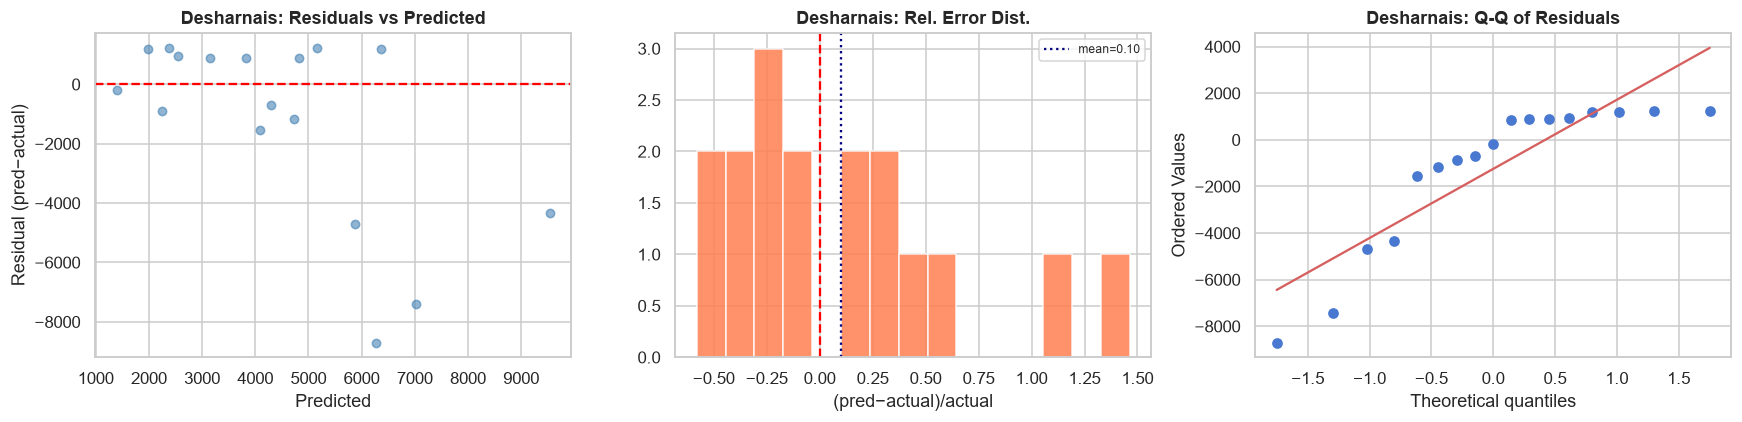

Saved: residuals_desharnais.png
  Bias=0.1003  PRED25=0.294  PRED50=0.706


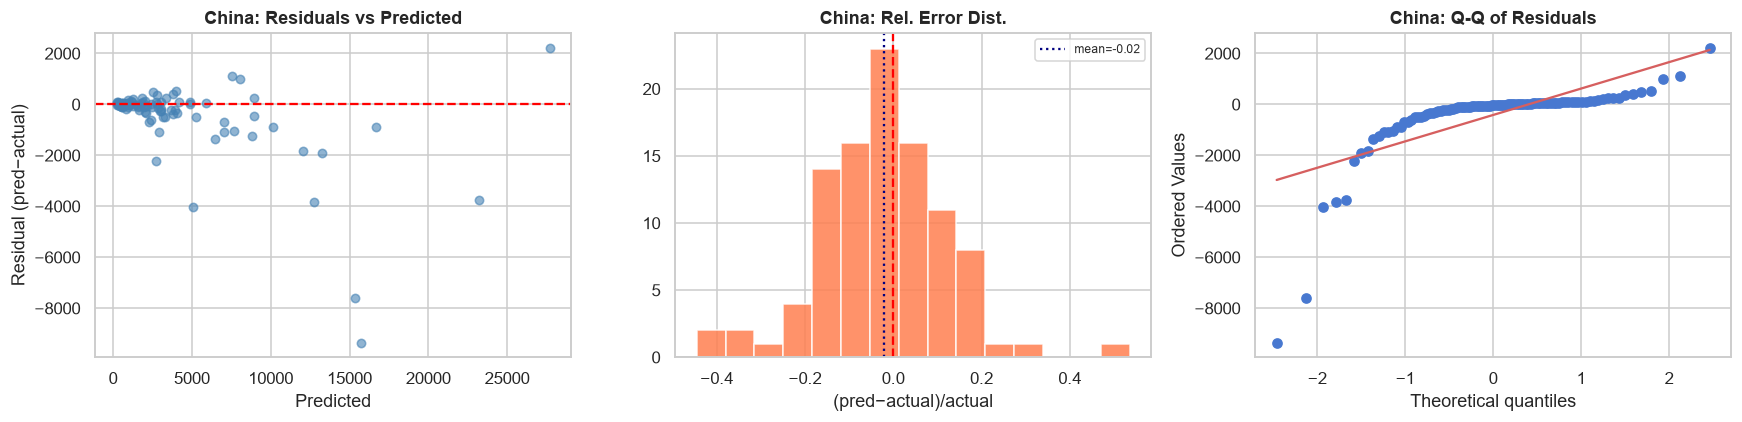

Saved: residuals_china.png
  Bias=-0.0218  PRED25=0.930  PRED50=0.990


In [19]:
for ds_name in ['Desharnais', 'China']:
    if ds_name not in all_datasets: continue
    meta = all_datasets[ds_name]; df = meta['df'].copy(); tgt = meta['target']
    df_tr, df_te = holdout_split(df, frac=0.20)
    X_tr_df = df_tr.drop(columns=[tgt])
    prep, _, _ = build_preprocessor(X_tr_df)
    X_tr = prep.fit_transform(X_tr_df)
    X_te = prep.transform(df_te.drop(columns=[tgt]))
    y_te = df_te[tgt].values

    rf = RandomForestRegressor(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1)
    rf.fit(X_tr, np.log1p(df_tr[tgt].values))
    yp = np.maximum(np.expm1(rf.predict(X_te)), 0)

    resid    = yp - y_te
    rel_err  = (yp - y_te) / np.maximum(y_te, 1e-9)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].scatter(yp, resid, alpha=0.6, s=30, color='steelblue')
    axes[0].axhline(0, color='red', ls='--')
    axes[0].set(xlabel='Predicted', ylabel='Residual (pred−actual)',
                title=f'{ds_name}: Residuals vs Predicted')
    axes[0].title.set_fontweight('bold')

    axes[1].hist(rel_err, bins=15, color='coral', edgecolor='white', alpha=0.85)
    axes[1].axvline(0, color='red', ls='--')
    axes[1].axvline(rel_err.mean(), color='navy', ls=':',
                    label=f'mean={rel_err.mean():.2f}')
    axes[1].set(xlabel='(pred−actual)/actual', title=f'{ds_name}: Rel. Error Dist.')
    axes[1].title.set_fontweight('bold'); axes[1].legend(fontsize=8)

    stats.probplot(resid, dist='norm', plot=axes[2])
    axes[2].set_title(f'{ds_name}: Q-Q of Residuals', fontweight='bold')

    plt.tight_layout()
    fname = f'residuals_{ds_name.lower()}.png'
    plt.savefig(fname, bbox_inches='tight', dpi=110)
    plt.show(); print(f'Saved: {fname}')
    print(f'  Bias={rel_err.mean():.4f}  PRED25={pred_n(y_te,yp):.3f}  PRED50={pred_n(y_te,yp,0.50):.3f}')

## 13. Dataset Deep Dives

In [20]:
# ── Renzo-Pomodoro: human planning accuracy ───────────────────────
if 'Renzo-Pomodoro' in all_datasets:
    df_rp = all_datasets['Renzo-Pomodoro']['df'].copy()
    print(f'Renzo-Pomodoro: {len(df_rp)} task records (estimate + actual both known)')

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    lim = max(df_rp['estimate'].max(), df_rp['actual'].max())
    axes[0].scatter(df_rp['estimate'], df_rp['actual'], alpha=0.3, s=12, color='steelblue')
    axes[0].plot([0,lim],[0,lim],'r--',lw=1.5,label='Perfect')
    axes[0].set(xlabel='Estimate (pomodori)',ylabel='Actual (pomodori)',
                title='Task Estimate vs Actual'); axes[0].title.set_fontweight('bold')
    axes[0].legend(fontsize=8)

    rel = ((df_rp['actual']-df_rp['estimate'])/df_rp['estimate']).clip(-2,5)
    axes[1].hist(rel,bins=30,color='coral',edgecolor='white')
    axes[1].axvline(0,color='red',ls='--')
    axes[1].axvline(rel.median(),color='navy',ls=':',label=f'med={rel.median():.2f}')
    axes[1].set(xlabel='(actual−est)/est',title='Planning Accuracy Dist.')
    axes[1].title.set_fontweight('bold'); axes[1].legend(fontsize=8)

    dn = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
    dm = df_rp.groupby('day_of_week')['actual'].median()
    axes[2].bar([dn[int(d)] for d in dm.index],dm.values,color='mediumpurple')
    axes[2].set(xlabel='Day of Week',ylabel='Median actual',title='Effort by Day')
    axes[2].title.set_fontweight('bold')

    plt.suptitle('Renzo-Pomodoro: Agile Task-Level Analysis',fontweight='bold')
    plt.tight_layout()
    plt.savefig('renzo_analysis.png',bbox_inches='tight',dpi=100); plt.show()
    print(f'Human MMRE={mmre(df_rp.actual.values,df_rp.estimate.values):.3f}  '
          f'PRED25={pred_n(df_rp.actual.values,df_rp.estimate.values):.3f}')

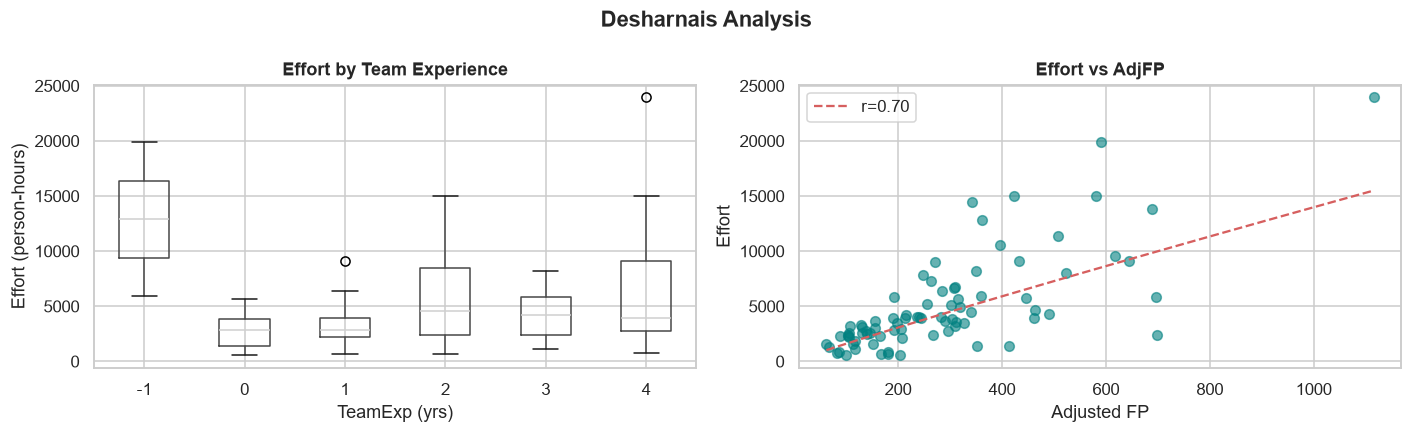

In [21]:
# ── Desharnais: Team Experience & FP vs Effort ────────────────────
if 'Desharnais' in all_datasets:
    df_d = all_datasets['Desharnais']['df'].copy(); tgt = 'Effort'
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    if 'TeamExp' in df_d.columns:
        df_d.boxplot(column=tgt, by='TeamExp', ax=axes[0])
        axes[0].set(title='Effort by Team Experience',
                    xlabel='TeamExp (yrs)', ylabel='Effort (person-hours)')
        axes[0].title.set_fontweight('bold')
    if 'PointsAjust' in df_d.columns:
        axes[1].scatter(df_d['PointsAjust'],df_d[tgt],alpha=0.6,s=40,color='teal')
        v = (df_d['PointsAjust']>0)&(df_d[tgt]>0)
        xl,yl = np.log(df_d.loc[v,'PointsAjust']),np.log(df_d.loc[v,tgt])
        sl,ic,r,*_ = stats.linregress(xl,yl)
        xr = np.linspace(xl.min(),xl.max(),100)
        axes[1].plot(np.exp(xr),np.exp(ic+sl*xr),'r--',lw=1.5,label=f'r={r:.2f}')
        axes[1].set(xlabel='Adjusted FP',ylabel='Effort',title='Effort vs AdjFP')
        axes[1].title.set_fontweight('bold'); axes[1].legend()
    plt.suptitle('Desharnais Analysis',fontweight='bold'); plt.tight_layout()
    plt.savefig('desharnais_analysis.png',bbox_inches='tight',dpi=100); plt.show()

## 14. Data Quality Report

In [22]:
print('='*70, '\n  DATA QUALITY REPORT\n', '='*70, sep='')
for name, meta in all_datasets.items():
    df = meta['df']; y = df[meta['target']]
    q1,q3 = y.quantile(0.25),y.quantile(0.75); iqr = q3-q1
    outliers = ((y<q1-3*iqr)|(y>q3+3*iqr)).sum()
    ratio = len(df)/max(len(df.columns)-1,1)
    adeq  = '✓ adequate' if ratio>=5 else '⚠ low (n/p<5)'
    print(f'\n{name}')
    print(f'  n={len(df):<6d} features={len(df.columns)-1:<4d} n/p={ratio:.1f} [{adeq}]')
    print(f'  Missing={df.isnull().mean().mean()*100:.2f}%  Outliers(3IQR)={outliers}  Dups={df.duplicated().sum()}')
    print(f'  Target: min={y.min():.1f}  median={y.median():.1f}  max={y.max():.1f}  unit={meta["unit"]}')
    print(f'  SHA-256: {meta["sha256"][:32]}...')

  DATA QUALITY REPORT

Albrecht
  n=24     features=7    n/p=3.4 [⚠ low (n/p<5)]
  Missing=0.00%  Outliers(3IQR)=3  Dups=0
  Target: min=0.5  median=11.4  max=105.2  unit=person-months
  SHA-256: cfd9713c6a0a45e318fd5345d3f45ac1...

China
  n=499    features=16   n/p=31.2 [✓ adequate]
  Missing=0.00%  Outliers(3IQR)=33  Dups=0
  Target: min=26.0  median=1829.0  max=54620.0  unit=person-hours
  SHA-256: ae9df9c52c5bc5ba03b9732ecc159093...

COCOMO-81
  n=63     features=17   n/p=3.7 [⚠ low (n/p<5)]
  Missing=0.00%  Outliers(3IQR)=5  Dups=0
  Target: min=5.9  median=98.0  max=11400.0  unit=person-months
  SHA-256: f7deb2ceffcb5f6631899e2439cbde5a...

Desharnais
  n=81     features=10   n/p=8.1 [✓ adequate]
  Missing=0.00%  Outliers(3IQR)=2  Dups=0
  Target: min=546.0  median=3647.0  max=23940.0  unit=person-hours
  SHA-256: 38c5d00053555cbe7f3c10c2b026990e...

Finnish
  n=38     features=5    n/p=7.6 [✓ adequate]
  Missing=0.00%  Outliers(3IQR)=0  Dups=0
  Target: min=460.0  median=5430.0

## 15. Approval Gate Report & Export

In [23]:
print('='*70)
print('  FINAL APPROVAL GATE REPORT')
print(f'  {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}  |  seed={RANDOM_SEED}  |  split=80/20')
print('='*70)
print(f'  Gate: PRED25 >= {GATE["min_PRED25"]:.0%} AND MAE < baseline AND n >= {MIN_ROWS_APPROVE}')

for ds_name, res in all_results.items():
    n = len(all_datasets.get(ds_name,{}).get('df',[]))
    approved     = [r for r in res if r.get('status')=='APPROVED']
    experimental = [r for r in res if r.get('status')=='EXPERIMENTAL']
    rejected     = [r for r in res if r.get('status')=='REJECTED']
    print(f"\n{'─'*50}  {ds_name} (n={n})")
    for r in approved:
        print(f"  ✓ APPROVED      {r['model']:20s} MAE={r.get('MAE')}  PRED25={r.get('PRED25')}")
    for r in experimental:
        print(f"  ~ EXPERIMENTAL  {r['model']:20s} MAE={r.get('MAE')}  ({r.get('reason','')})"
             )
    for r in rejected:
        print(f"  ✗ REJECTED      {r['model']:20s} [{r.get('reason','')}]")

n_ap = sum(1 for rs in all_results.values() for r in rs if r.get('status')=='APPROVED')
n_ex = sum(1 for rs in all_results.values() for r in rs if r.get('status')=='EXPERIMENTAL')
n_re = sum(1 for rs in all_results.values() for r in rs if r.get('status')=='REJECTED')
print(f"\n{'='*70}")
print(f'  TOTAL: {n_ap} APPROVED  |  {n_ex} EXPERIMENTAL  |  {n_re} REJECTED')
print(f"{'='*70}")

  FINAL APPROVAL GATE REPORT
  2026-10-11 12:50:37  |  seed=42  |  split=80/20
  Gate: PRED25 >= 30% AND MAE < baseline AND n >= 25

──────────────────────────────────────────────────  Albrecht (n=24)
  ~ EXPERIMENTAL  ABE_k3               MAE=7.98  (n=24 < 25 (too small for APPROVED))
  ~ EXPERIMENTAL  Ridge                MAE=2.64  (n=24 < 25 (too small for APPROVED))
  ~ EXPERIMENTAL  HuberRegressor       MAE=6.37  (n=24 < 25 (too small for APPROVED))
  ~ EXPERIMENTAL  RandomForest         MAE=3.63  (n=24 < 25 (too small for APPROVED))
  ~ EXPERIMENTAL  GradBoost            MAE=5.59  (n=24 < 25 (too small for APPROVED))
  ~ EXPERIMENTAL  DecisionTree         MAE=6.5  (n=24 < 25 (too small for APPROVED))
  ~ EXPERIMENTAL  XGBoost              MAE=6.85  (n=24 < 25 (too small for APPROVED))

──────────────────────────────────────────────────  China (n=499)
  ✓ APPROVED      ABE_k3               MAE=1537.94  PRED25=0.45
  ✓ APPROVED      RandomForest         MAE=577.08  PRED25=0.93
  ✓ 

In [24]:
# ── Export ────────────────────────────────────────────────────────
results_df.to_csv('evaluation_results_all.csv', index=False)
best.to_csv('evaluation_results_best.csv', index=False)

provenance = {
    'generated_at': datetime.now().isoformat(),
    'random_seed' : RANDOM_SEED,
    'gate'        : GATE,
    'min_rows_for_approval': MIN_ROWS_APPROVE,
    'datasets'    : {
        name: {'source': m['source'], 'n': len(m['df']),
               'target': m['target'], 'unit': m['unit'], 'sha256': m['sha256']}
        for name, m in all_datasets.items()
    },
    'note': ('All values computed from real PROMISE SERepo datasets. '
             'No synthetic data used. Metrics from held-out test sets only.')
}
with open('provenance.json','w') as f:
    json.dump(provenance, f, indent=2)

print('Exported:')
for fn in ['evaluation_results_all.csv','evaluation_results_best.csv','provenance.json']:
    sz = Path(fn).stat().st_size if Path(fn).exists() else 0
    print(f'  {fn} ({sz} bytes)')
print('Charts: target_distributions.png, corr_china.png,')
print('        model_comparison_summary.png, actual_vs_predicted.png,')
print('        cv_results.png, feature_importance_china.png,')
print('        residuals_desharnais.png, residuals_china.png,')
print('        renzo_analysis.png, desharnais_analysis.png')

Exported:
  evaluation_results_all.csv (9075 bytes)
  evaluation_results_best.csv (715 bytes)
  provenance.json (2996 bytes)
Charts: target_distributions.png, corr_china.png,
        model_comparison_summary.png, actual_vs_predicted.png,
        cv_results.png, feature_importance_china.png,
        residuals_desharnais.png, residuals_china.png,
        renzo_analysis.png, desharnais_analysis.png


---
## Notes & Limitations

| Item | Detail |
|------|--------|
| **Units** | Each dataset has its own unit. Models are per-dataset — units never mixed. |
| **Log transform** | Effort is right-skewed; train on `log₁₊(effort)`, invert predictions. |
| **Leakage guards applied** | `CostPerFP`, `Actual des` (Subbiah) · `Real_P20` (UCP) · `HH_CFP` (Valdes-Souto) · `lneff`, `lnsize` (Finnish) · `N_effort` (China) · `Time` (Maxwell) · `Estimated.completion.date` (Kitchenham) |
| **Small datasets** | n < 25 → ML output labelled EXPERIMENTAL, never APPROVED |
| **No synthetic data** | Every number comes from the 13 files in `dataset/` |
| **Source** | PROMISE Software Engineering Repository — cite per their guidelines |
